Epoch 1/50


c:\Users\Asad\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 203ms/step - loss: 0.2863 - root_mean_squared_error: 0.5323 - val_loss: 0.0050 - val_root_mean_squared_error: 0.0707
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0248 - root_mean_squared_error: 0.1566 - val_loss: 0.0439 - val_root_mean_squared_error: 0.2095
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0444 - root_mean_squared_error: 0.2106 - val_loss: 0.0283 - val_root_mean_squared_error: 0.1681
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0140 - root_mean_squared_error: 0.1175 - val_loss: 0.0087 - val_root_mean_squared_error: 0.0932
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0170 - root_mean_squared_error: 0.1302 - val_loss: 0.0059 - val_root_mean_squared_error: 0.0768
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0256 - root_mean_squared_error: 0.1593 - val_loss: 0.0084 - val_root_mean_squared_error: 0.0915
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0103 - root_mean_squa

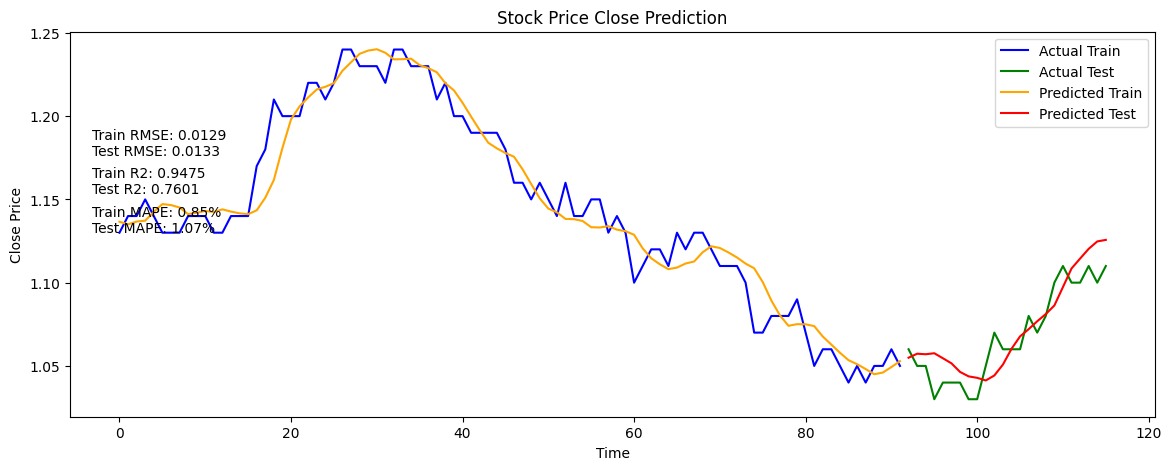

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import RootMeanSquaredError
from sklearn.metrics import mean_squared_error, r2_score
import joblib

# Function to create sequences
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data.iloc[i:(i + seq_length)].values
        y = data.iloc[i + seq_length]['Close']
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

# Fetch data from Yahoo Finance
def fetch_data(stock_code, interval='30m', period='3mo'):
    ticker = yf.Ticker(stock_code)
    data = ticker.history(interval=interval, period=period)
    return data

# Feature Engineering: Add technical indicators
def add_indicators(df):
    df['RSI'] = compute_RSI(df['Close'])
    df['MACD'], df['MACD_Signal'] = compute_MACD(df['Close'])
    df.dropna(inplace=True)
    return df

# Compute RSI
def compute_RSI(series, period=14):
    delta = series.diff(1)
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.rolling(window=period).mean()
    avg_loss = loss.rolling(window=period).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Compute MACD
def compute_MACD(series, short_period=12, long_period=26, signal_period=9):
    short_ema = series.ewm(span=short_period, adjust=False).mean()
    long_ema = series.ewm(span=long_period, adjust=False).mean()
    macd = short_ema - long_ema
    macd_signal = macd.ewm(span=signal_period, adjust=False).mean()
    return macd, macd_signal

# Process the data
def process_data(df, seq_length):
    df = add_indicators(df)
    scaler = MinMaxScaler(feature_range=(0, 1))
    
    # Scale features and target separately
    feature_columns = ['Open', 'High', 'Low', 'Close', 'Volume', 'RSI', 'MACD']
    scaled_features = scaler.fit_transform(df[feature_columns])
    
    df_scaled = pd.DataFrame(scaled_features, columns=feature_columns, index=df.index)
    
    X, y = create_sequences(df_scaled, seq_length)
    
    train_size = int(len(X) * 0.8)
    X_train, y_train = X[:train_size], y[:train_size]
    X_test, y_test = X[train_size:], y[train_size:]

    # Save the scaler
    joblib.dump(scaler, 'scaler.pkl')
    
    return X_train, y_train, X_test, y_test, scaler

# Build the BiLSTM model
def build_bilstm_model(input_shape):
    model = Sequential()
    model.add(Bidirectional(LSTM(100, return_sequences=True), input_shape=input_shape))
    model.add(Bidirectional(LSTM(100, return_sequences=False)))
    model.add(Dropout(0.2))
    model.add(Dense(50, activation='relu'))
    model.add(Dense(1, activation='linear'))

    cp = ModelCheckpoint('model.keras', save_best_only=True)
    model.compile(optimizer='adam', loss=MeanSquaredError(), metrics=[RootMeanSquaredError()])
    return model, cp

# Train the model
def train_model(X_train, y_train, X_test, y_test, seq_length):
    model, cp = build_bilstm_model((seq_length, X_train.shape[2]))
    history = model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=50, batch_size=32, callbacks=[cp])
    return model, history

# Evaluate and plot results with metrics
def evaluate_and_plot_with_metrics(model, X_train, y_train, X_test, y_test, scaler):
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    
    # Construct arrays with the same shape expected by the scaler
    train_features_dummy = np.zeros((train_predictions.shape[0], 7))
    test_features_dummy = np.zeros((test_predictions.shape[0], 7))
    
    # Place the predictions in the 'Close' position
    train_features_dummy[:, 3] = train_predictions[:, 0]  # Assuming 'Close' is the 4th column
    test_features_dummy[:, 3] = test_predictions[:, 0]    # Assuming 'Close' is the 4th column
    
    # Inverse transform the predictions
    train_predictions_rescaled = scaler.inverse_transform(train_features_dummy)[:, 3]
    test_predictions_rescaled = scaler.inverse_transform(test_features_dummy)[:, 3]
    
    # Inverse transform the actual values
    y_train_dummy = np.zeros((y_train.shape[0], 7))
    y_test_dummy = np.zeros((y_test.shape[0], 7))
    y_train_dummy[:, 3] = y_train
    y_test_dummy[:, 3] = y_test
    
    y_train_rescaled = scaler.inverse_transform(y_train_dummy)[:, 3]
    y_test_rescaled = scaler.inverse_transform(y_test_dummy)[:, 3]
    
    # Calculate metrics
    train_rmse = np.sqrt(mean_squared_error(y_train_rescaled, train_predictions_rescaled))
    test_rmse = np.sqrt(mean_squared_error(y_test_rescaled, test_predictions_rescaled))
    train_r2 = r2_score(y_train_rescaled, train_predictions_rescaled)
    test_r2 = r2_score(y_test_rescaled, test_predictions_rescaled)
    train_mape = np.mean(np.abs((y_train_rescaled - train_predictions_rescaled) / y_train_rescaled)) * 100
    test_mape = np.mean(np.abs((y_test_rescaled - test_predictions_rescaled) / y_test_rescaled)) * 100
    
    # Plotting results
    plt.figure(figsize=(14, 5))
    plt.plot(y_train_rescaled, color='blue', label='Actual Train')
    plt.plot(np.arange(len(y_train_rescaled), len(y_train_rescaled) + len(y_test_rescaled)), y_test_rescaled, color='green', label='Actual Test')
    plt.plot(train_predictions_rescaled, color='orange', label='Predicted Train')
    plt.plot(np.arange(len(y_train_rescaled), len(y_train_rescaled) + len(y_test_rescaled)), test_predictions_rescaled, color='red', label='Predicted Test')
    
    # Add text labels for metrics
    plt.text(0.02, 0.75, f'Train RMSE: {train_rmse:.4f}\nTest RMSE: {test_rmse:.4f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')
    plt.text(0.02, 0.65, f'Train R2: {train_r2:.4f}\nTest R2: {test_r2:.4f}', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')
    plt.text(0.02, 0.55, f'Train MAPE: {train_mape:.2f}%\nTest MAPE: {test_mape:.2f}%', transform=plt.gca().transAxes, fontsize=10, verticalalignment='top')
    
    plt.xlabel('Time')
    plt.ylabel('Close Price')
    plt.title('Stock Price Close Prediction')
    plt.legend()
    plt.show()

# Fetch data for the stock
stock_data = fetch_data('5148.KL', interval='1h', period='1mo')

# Process and train the model
seq_length = 4  # Example sequence length
df_selected = pd.DataFrame(stock_data)
X_train, y_train, X_test, y_test, scaler = process_data(df_selected, seq_length)

model, history = train_model(X_train, y_train, X_test, y_test, seq_length)

# Evaluate and plot results with metrics
evaluate_and_plot_with_metrics(model, X_train, y_train, X_test, y_test, scaler)
